# Embeddings: from Co-occurrence Counts to Word2Vec

We build word vectors in two different ways, on the same corpus, and compare them:

- **count-based**: a word-context matrix, weighted with PPMI and compressed with SVD;
- **prediction-based**: Word2Vec (skip-gram), and FastText, which adds subword information.

Then we look at what the vectors capture: nearest neighbours, words with more than one meaning,
misspellings, analogies and biases. At the end we go from words to **documents**: the simplest way to
represent a text with word vectors is to average them, and Doc2Vec learns a vector for the whole document.

The corpus is **20 Newsgroups**, a collection of posts from 20 discussion groups on very different topics.

In [1]:
# Run once if you are not using the course environment.
# %pip install -q numpy pandas scipy scikit-learn matplotlib gensim

In [2]:
import contextlib
import io
import re
import time
import zlib
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

import gensim.downloader as api
from gensim.models import FastText, KeyedVectors, Word2Vec
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

import sys
sys.unraisablehook = lambda unraisable: None  # hides the harmless messages of gensim's C code


pd.set_option("display.max_colwidth", None)

---
## The data

We remove headers, signatures and quoted replies, which would reveal the group of a post. We learn the
vectors on the training posts. The newsgroup of a post is never used to train anything: we use it only
at the end, to evaluate the document vectors.

In [3]:
remove = ("headers", "footers", "quotes")
train = fetch_20newsgroups(subset="train", remove=remove)
test = fetch_20newsgroups(subset="test", remove=remove)

print(len(train.data), "training posts,", len(test.data), "test posts")
print(train.target_names)
print()

i = np.where(train.target == train.target_names.index("sci.space"))[0][0]
print("newsgroup:", train.target_names[train.target[i]])
print(train.data[i][:600])

11314 training posts, 7532 test posts
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

newsgroup: sci.space
From article <C5owCB.n3p@world.std.com>, by tombaker@world.std.com (Tom A Baker):


My understanding is that the 'expected errors' are basically
known bugs in the warning system software - things are checked
that don't have the right values in yet because they aren't
set till after launch, and suchlike. Rather than fix the code
and possibly introduce new bugs, they just tell the crew
'ok, if you see a warning no. 213 before liftoff, ignore it'.


We keep the tokenizer very simple: lowercase, and sequences of letters (with an inner apostrophe).
Every representation below is built from the **same tokens**, so the comparison is fair. A few posts
are empty or very short, and we drop them.

In [4]:
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

train_tokens = [tokenize(t) for t in train.data]
test_tokens = [tokenize(t) for t in test.data]

keep_train = [i for i, d in enumerate(train_tokens) if len(d) >= 20]  # Keep only posts with at least 20 tokens
keep_test = [i for i, d in enumerate(test_tokens) if len(d) >= 20]
train_tokens = [train_tokens[i] for i in keep_train]
test_tokens = [test_tokens[i] for i in keep_test]
train_labels = train.target[keep_train]
test_labels = test.target[keep_test]

n_tokens = sum(len(d) for d in train_tokens)
print(f"{len(train_tokens):,} training posts, {n_tokens:,} tokens, {len(set(w for d in train_tokens for w in d)):,} distinct words")
print(train_tokens[i][:25])

10,116 training posts, 2,267,517 tokens, 75,597 distinct words
['of', 'course', 'the', 'term', 'must', 'be', 'rigidly', 'defined', 'in', 'any', 'bill', 'i', 'doubt', 'she', 'uses', 'this', 'term', 'for', 'that', 'you', 'are', 'using', 'a', 'quote', 'allegedly']


---
## A word-context matrix

The **distributional hypothesis** says that words occurring in similar contexts have similar meanings.
We turn it into numbers: a matrix $\mathbf{Z}$ with one row per word and one column per context word.
The cell $z_{wc}$ counts how many times $c$ appears within $m$ tokens of $w$.

We keep the words that occur at least 10 times, so that every row has enough evidence.

In [5]:
MIN_COUNT = 10
WINDOW = 5  # m: tokens on each side of the center word

counts = Counter(w for d in train_tokens for w in d)
vocab = [w for w, c in counts.most_common() if c >= MIN_COUNT]
w2i = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f"vocabulary: {V:,} words")

vocabulary: 12,619 words


In [6]:
def cooccurrence_matrix(token_docs, w2i, window):
    # Z[w, c] = number of times c occurs within `window` tokens of w.
    V = len(w2i)
    Z = sp.csr_matrix((V, V), dtype=np.float32)
    rows, cols = [], []

    def flush(Z):
        r, c = np.concatenate(rows), np.concatenate(cols)
        ones = np.ones(len(r), dtype=np.float32)
        # each pair counts for both words: (w, c) and (c, w)
        Z = Z + sp.coo_matrix((ones, (r, c)), shape=(V, V)).tocsr()
        Z = Z + sp.coo_matrix((ones, (c, r)), shape=(V, V)).tocsr()
        rows.clear()
        cols.clear()
        return Z

    for n, doc in enumerate(token_docs, start=1):
        ids = np.array([w2i[w] for w in doc if w in w2i], dtype=np.int32)
        for k in range(1, window + 1):
            if len(ids) > k:
                rows.append(ids[:-k])
                cols.append(ids[k:])
        if n % 1000 == 0:
            Z = flush(Z)
    return flush(Z) if rows else Z

t0 = time.time()
Z = cooccurrence_matrix(train_tokens, w2i, WINDOW)
print(f"{Z.shape[0]:,} x {Z.shape[1]:,} matrix, {Z.nnz:,} non-zero cells "
      f"({100 * Z.nnz / V**2:.1f}% of the cells), built in {time.time() - t0:.1f}s")

12,619 x 12,619 matrix, 4,199,956 non-zero cells (2.6% of the cells), built in 1.2s


Each row is the **usage signature** of a word. These are the contexts with the largest counts for
*space*:

In [7]:
row = Z[w2i["space"]].toarray().ravel()
best = np.argsort(-row)[:10]
[(vocab[j], int(row[j])) for j in best]

[('the', 717),
 ('of', 378),
 ('and', 350),
 ('to', 285),
 ('a', 263),
 ('in', 253),
 ('space', 210),
 ('is', 173),
 ('for', 164),
 ('on', 113)]

The largest counts are for function words (*the*, *of*, *and*, *to*): they appear next to every word, and
they say nothing about what is special in the usage of *space*. Raw counts are dominated by frequency.

To compare two words we compare their rows with the **cosine similarity**. If the rows are first
scaled to unit length, the cosine is just a dot product, so all the similarities of a word can be
computed with one matrix product.

The helper below returns the nearest neighbours of a word, and it works for sparse and dense matrices.

In [8]:
def neighbors(Mn, word, k=8):
    # Nearest words by cosine. Mn must have unit-length rows.
    sims = Mn @ Mn[w2i[word]].T
    sims = sims.toarray().ravel() if sp.issparse(sims) else np.asarray(sims).ravel()
    best = np.argsort(-sims)[1:k + 1]  # position 0 is the word itself
    return [vocab[j] for j in best]

def similarity(Mn, a, b):
    s = Mn[w2i[a]] @ Mn[w2i[b]].T
    return float(s.toarray()[0, 0] if sp.issparse(s) else s)

Zn = normalize(Z)
probe = ["space", "god", "car", "game", "drive", "president"]
{w: neighbors(Zn, w) for w in probe}

{'space': ['launch',
  'development',
  'national',
  'society',
  'and',
  'material',
  'the',
  'general'],
 'god': ['jesus', 'one', 'the', 'life', 'death', 'truth', 'all', 'hell'],
 'car': ['with', 'while', 'for', 'bike', 'system', 'big', 'company', 'on'],
 'game': ['of', 'first', 'second', 'team', 'in', 'on', 'after', 'season'],
 'drive': ['disk',
  'machine',
  'cable',
  'system',
  'with',
  'tape',
  'for',
  'card'],
 'president': ['government',
  'of',
  'first',
  'bible',
  'in',
  'church',
  'same',
  'entire']}

---
## Weighting with PPMI

Raw counts reward words that are frequent *everywhere*. The **pointwise mutual information** asks
instead how much more often $w$ and $c$ occur together than they would if they were independent:

$$
\text{PMI}(w, c) = \log_2 \frac{P(w, c)}{P(w)\,P(c)}
\qquad
\text{PPMI}(w, c) = \max\big(0,\ \text{PMI}(w, c)\big)
$$

Negative values, which are noisy for rare pairs, are set to zero. A common refinement, called
*context distribution smoothing*, raises the context counts to the power $\alpha = 0.75$ before
computing $P(c)$, which gives rare contexts a little more weight.

In [9]:
def ppmi(Z, alpha=1.0):
    Zc = Z.tocoo()
    row_sum = np.asarray(Z.sum(axis=1)).ravel()
    col_sum = np.asarray(Z.sum(axis=0)).ravel() ** alpha
    pmi = np.log2(Zc.data * col_sum.sum() / (row_sum[Zc.row] * col_sum[Zc.col]))
    P = sp.csr_matrix((np.maximum(pmi, 0), (Zc.row, Zc.col)), shape=Z.shape)
    P.eliminate_zeros()
    return P

P1 = ppmi(Z, alpha=1.0)
P75 = ppmi(Z, alpha=0.75)

P1n, P75n = normalize(P1), normalize(P75)
print("alpha = 1.00")
for w in probe:
    print(f"  {w:9s}", neighbors(P1n, w))
print("alpha = 0.75")
for w in probe:
    print(f"  {w:9s}", neighbors(P75n, w))

alpha = 1.00
  space     ['nasa', 'shuttle', 'launch', 'satellite', 'planetary', 'telescope', 'and', 'national']
  god       ['jesus', 'that', "god's", 'christ', 'he', 'his', 'not', 'of']
  car       ['cars', 'a', 'bike', 'my', 'miles', 'engine', 'and', 'tires']
  game      ['games', 'team', 'season', 'play', 'hockey', 'won', 'played', 'chicago']
  drive     ['drives', 'floppy', 'disk', 'hard', 'ide', 'mb', 'controller', 'scsi']
  president ['stephanopoulos', 'clinton', 'mr', 'vice', 'secretary', 'senator', 'executive', 'congress']
alpha = 0.75
  space     ['nasa', 'shuttle', 'launch', 'planetary', 'satellite', 'telescope', 'missions', 'lunar']
  god       ['jesus', "god's", 'christ', 'lord', 'spirit', 'faith', 'bible', 'that']
  car       ['cars', 'bike', 'miles', 'tires', 'engine', 'dealer', 'toyota', 'driving']
  game      ['games', 'team', 'season', 'play', 'played', 'won', 'hockey', 'scored']
  drive     ['drives', 'floppy', 'disk', 'ide', 'hard', 'mb', 'controller', 'scsi']
  pre

---
## SVD: from sparse to dense

The PPMI rows still have as many coordinates as the vocabulary, and most of them are zero.
A truncated **singular value decomposition** compresses the matrix into $d$ dimensions while keeping
as much of its structure as possible.

In [10]:
D = 100  # d: embedding dimension

t0 = time.time()
svd = TruncatedSVD(n_components=D, random_state=0)
U = svd.fit_transform(P75)  # rows of U_d * Sigma_d
print(f"SVD vectors: {U.shape}, computed in {time.time() - t0:.1f}s")

Un = normalize(U)
{w: neighbors(Un, w) for w in probe}

SVD vectors: (12619, 100), computed in 1.1s


{'space': ['shuttle',
  'nasa',
  'nasda',
  'exploration',
  'launch',
  'planetary',
  'orbital',
  'flight'],
 'god': ["god's",
  'christ',
  'jesus',
  'sin',
  'spirit',
  'eternal',
  'faith',
  'sins'],
 'car': ['cars', 'bike', 'honda', 'tires', 'miles', 'rear', 'toyota', 'truck'],
 'game': ['games',
  'season',
  'team',
  'played',
  'playoffs',
  'score',
  'scored',
  'teams'],
 'drive': ['drives',
  'floppy',
  'disk',
  'controller',
  'hard',
  'ide',
  'maxtor',
  'esdi'],
 'president': ['senator',
  'secretary',
  'clinton',
  'stephanopoulos',
  'mr',
  "president's",
  'briefing',
  'meeting']}

---
## Word2Vec

Word2Vec does not count. It trains a small neural network to **predict the context words of a word**
(skip-gram), and the parameters of the network are the embeddings.

We use the same window, the same minimum count and the same dimension as above, so that the only
difference is the method.

In [11]:
def stable_hash(word):
    # gensim initializes each word vector from a hash of the word. Python's own
    # hash changes at every run, this one does not.
    return zlib.crc32(word.encode("utf8"))

t0 = time.time()
w2v = Word2Vec(train_tokens, vector_size=D, window=WINDOW, min_count=MIN_COUNT,
               sg=1, negative=5, epochs=5, workers=4, seed=0, hashfxn=stable_hash)
print(f"Word2Vec: {len(w2v.wv):,} words, trained in {time.time() - t0:.1f}s")

w2v.wv["space"][:8]

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec: 12,619 words, trained in 11.1s


array([ 0.13922031, -0.36874777,  0.29652697, -0.56565595,  0.5787953 ,
        0.34674093, -0.568616  , -0.32983318], dtype=float32)

The embedding of a word is a plain vector of $d = 100$ numbers (we print the first eight).
The nearest neighbours by cosine similarity:

In [12]:
{w: [x for x, _ in w2v.wv.most_similar(w, topn=8)] for w in probe}

{'space': ['shuttle',
  'planetary',
  'nasa',
  'manned',
  'flight',
  'goddard',
  'astronaut',
  'hubble'],
 'god': ['christ',
  "god's",
  'salvation',
  'faith',
  'allah',
  'jesus',
  'spirit',
  'lord'],
 'car': ['bicycle',
  'bike',
  'bmw',
  'convertible',
  'volvo',
  'porsche',
  'odometer',
  'tires'],
 'game': ['games',
  'shutouts',
  'champ',
  'score',
  'playoffs',
  'stanley',
  'pennant',
  'blues'],
 'drive': ['floppy',
  'drives',
  'controller',
  'hd',
  'esdi',
  'conner',
  'prodrive',
  'ide'],
 'president': ['senator',
  'yeltsin',
  'secretary',
  'clinton',
  'bush',
  'miyazawa',
  'stephanopoulos',
  'myers']}

### The four methods side by side

Same corpus, same words. The cells show the nearest neighbours of each probe word.

In [13]:
k = 6
pd.DataFrame({
    "counts": {w: ", ".join(neighbors(Zn, w, k)) for w in probe},
    "PPMI": {w: ", ".join(neighbors(P75n, w, k)) for w in probe},
    "PPMI + SVD": {w: ", ".join(neighbors(Un, w, k)) for w in probe},
    "Word2Vec": {w: ", ".join(x for x, _ in w2v.wv.most_similar(w, topn=k)) for w in probe},
})

,counts,PPMI,PPMI + SVD,Word2Vec
space,"launch, development, national, society, and, material","nasa, shuttle, launch, planetary, satellite, telescope","shuttle, nasa, nasda, exploration, launch, planetary","shuttle, planetary, nasa, manned, flight, goddard"
god,"jesus, one, the, life, death, truth","jesus, god's, christ, lord, spirit, faith","god's, christ, jesus, sin, spirit, eternal","christ, god's, salvation, faith, allah, jesus"
car,"with, while, for, bike, system, big","cars, bike, miles, tires, engine, dealer","cars, bike, honda, tires, miles, rear","bicycle, bike, bmw, convertible, volvo, porsche"
game,"of, first, second, team, in, on","games, team, season, play, played, won","games, season, team, played, playoffs, score","games, shutouts, champ, score, playoffs, stanley"
drive,"disk, machine, cable, system, with, tape","drives, floppy, disk, ide, hard, mb","drives, floppy, disk, controller, hard, ide","floppy, drives, controller, hd, esdi, conner"
president,"government, of, first, bible, in, church","stephanopoulos, mr, clinton, vice, secretary, senator","senator, secretary, clinton, stephanopoulos, mr, president's","senator, yeltsin, secretary, clinton, bush, miyazawa"


Things to notice:

- **Counts** are dominated by frequent words: the neighbours of *car* include *with* and *for*, those of
  *game* include *of*, *in* and *on*. A frequent word co-occurs with almost everything.
- **PPMI** removes most of that effect: *car* is now close to *cars*, *bike*, *miles*, *tires*, *engine*.
- **SVD** keeps the structure of PPMI in 100 dimensions, and the neighbours stay topical: *drive* is close
  to *drives*, *floppy*, *disk*, *controller*.
- **Word2Vec** returns words of the same domain, often very specific: *car* is close to *convertible*, *camry*,
  *volvo*; *game* to *stanley*, *playoffs*, *inning*; *president* to *yeltsin*, *clinton*, *miyazawa*.

---
## What the hyperparameters change

The **window** decides what counts as context. A short window sees the immediate neighbours of a word
(more syntactic information), a long window sees the whole sentence or more (more topical information).
Another choice is the architecture: skip-gram predicts the context from the word, CBOW predicts the word
from its context.

In [14]:
variants = {
    "skip-gram, window 2": dict(sg=1, window=2),
    "skip-gram, window 10": dict(sg=1, window=10),
    "CBOW, window 5": dict(sg=0, window=5),
}

rows = {}
for name, params in variants.items():
    t0 = time.time()
    m = Word2Vec(train_tokens, vector_size=D, min_count=MIN_COUNT, negative=5, epochs=5,
                 workers=4, seed=0, hashfxn=stable_hash, **params)
    rows[name] = {w: ", ".join(x for x, _ in m.wv.most_similar(w, topn=6)) for w in ["game", "space"]}
    rows[name]["seconds"] = round(time.time() - t0, 1)

pd.DataFrame(rows).T

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

,game,space,seconds
"skip-gram, window 2","playoffs, wins, rookie, season, goalie, goaltender","planetary, shuttle, lunar, nasa, launch, research",5.9
"skip-gram, window 10","played, stanley, scored, shutouts, goalies, games","shuttle, astronaut, planetary, exploration, hubble, telescope",18.6
"CBOW, window 5","season, team, games, playoffs, flyers, score","shuttle, launch, satellite, lunar, technology, research",3.1


The neighbours of *game* and *space* stay in the same topic in every variant, and the differences are small:
the longer window brings more words of the topic (*inning*, *shutouts*, *goalies* for *game*), the shorter one more
words that play a similar role (*playoffs*, *streak*, *rookie*). The cost changes more: training time grows with the
window, and CBOW is the fastest. To see the effect of a hyperparameter we need to look at many words, and
this is why embeddings are evaluated on benchmarks.

---
## Close in meaning, or close in context?

The vectors place words by **where they occur**, not by what they mean. *Good* and *bad* are opposite
in polarity, but they appear in the same kinds of sentences, so their contexts are very similar.
The cosine similarity of some pairs, for each representation:

In [15]:
pairs = [("good", "great"), ("good", "bad"), ("love", "hate"),
         ("space", "orbit"), ("space", "disk"), ("hockey", "baseball"), ("good", "the")]

pd.DataFrame({
    "counts": [similarity(Zn, a, b) for a, b in pairs],
    "PPMI": [similarity(P75n, a, b) for a, b in pairs],
    "PPMI + SVD": [similarity(Un, a, b) for a, b in pairs],
    "Word2Vec": [w2v.wv.similarity(a, b) for a, b in pairs],
}, index=[f"{a} / {b}" for a, b in pairs]).round(2)

,counts,PPMI,PPMI + SVD,Word2Vec
good / great,0.94,0.19,0.73,0.64
good / bad,0.95,0.23,0.78,0.70
love / hate,0.90,0.12,0.71,0.67
space / orbit,0.86,0.22,0.58,0.47
space / disk,0.83,0.12,0.25,0.39
hockey / baseball,0.92,0.18,0.66,0.77
good / the,0.85,0.14,0.35,0.27


With raw counts almost every pair has a very high cosine, even *good* and *the*: frequent words dominate
the rows, and the similarity says little. PPMI gives low cosines for all the pairs, because its rows are sparse.
With SVD and Word2Vec, *good* is as close to *bad* as it is to *great*, and *love* is close to *hate*. The
vectors capture a **shared way of being used**, which is not the same as sharing a meaning or a polarity.

There is also **one vector per word**, whatever its meaning. *Space* is outer space in *sci.space* and
disk space in the computer groups; *drive* is a disk drive or driving a car. Which senses do the vectors keep?

In [16]:
for w in ["space", "drive", "windows"]:
    print(f"{w:8s}", [x for x, _ in w2v.wv.most_similar(w, topn=10)])

space    ['shuttle', 'planetary', 'nasa', 'manned', 'flight', 'goddard', 'astronaut', 'hubble', 'sts', 'exploration']
drive    ['floppy', 'drives', 'controller', 'hd', 'esdi', 'conner', 'prodrive', 'ide', 'controllers', 'seagate']
windows  ['apps', 'microsoft', 'workgroups', 'excel', 'linux', 'povray', 'ver', 'sys', 'emm', 'autoexec']


The neighbours show the **dominant sense** of each word in this corpus: *space* is outer space (*shuttle*,
*planetary*, *astronaut*), *drive* is a disk drive (*floppy*, *ide*, *controller*), and *windows* is only the operating
system. The other senses (disk space, driving a car) are almost invisible among the neighbours. The vector is
one for all the senses, a **blend dominated by the most frequent one**. A trace of the other sense remains:
in the table above, *space* is as close to *disk* as to *orbit* for Word2Vec.

Do the vectors group the words by topic? We colour every word by the **kind of newsgroup** in which it is
most concentrated (*comp*, *rec*, *sci*, *talk*, ...), take the most characteristic words of each kind,
and project their Word2Vec vectors to two dimensions.

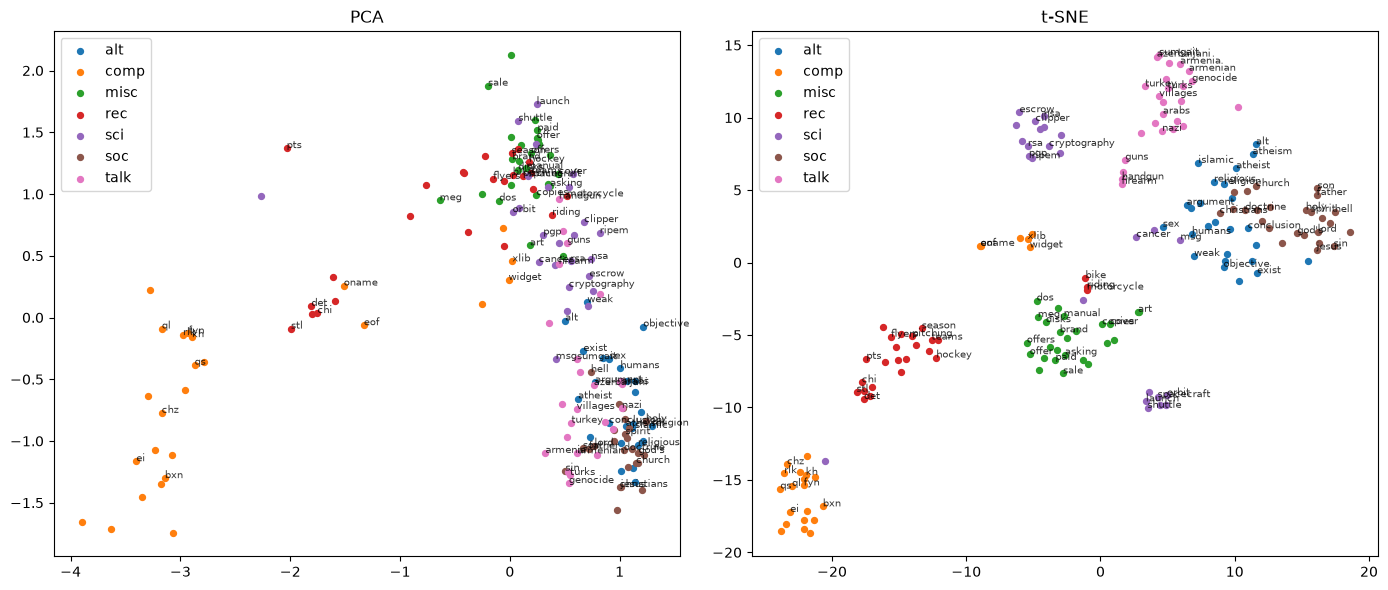

In [17]:
# group the 20 newsgroups by their first name: "comp.graphics" -> "comp", "sci.space" -> "sci", ...
group_names = sorted({name.split(".")[0] for name in train.target_names})
group_of_class = np.array([group_names.index(name.split(".")[0]) for name in train.target_names])
doc_group = group_of_class[train_labels]  # for every training post, the number of its group

# count how many times every word occurs in the posts of each group. word_group[i, g] = occurrences of the word i in the posts of the group g
word_group = np.zeros((V, len(group_names)))
for doc, g in zip(train_tokens, doc_group):
    for w in doc:
        if w in w2i:  # only the words of the vocabulary
            word_group[w2i[w], g] += 1

# "where is the word concentrated?" We compare two numbers for every group:
share = word_group / word_group.sum(axis=1, keepdims=True)  # share of the occurrences of a word that falls in each group
base = np.bincount(doc_group, minlength=len(group_names)) / len(doc_group)  # share of the posts that belong to each group
lift = share / base  # > 1: the word is more frequent in that group than the size of the group would suggest

# For every group, keep the 25 words with the highest lift, among the words that occur at least 100 times (to avoid very rare words)
frequent = np.where(word_group.sum(axis=1) >= 100)[0]
words, colors = [], []
for g in range(len(group_names)):
    best = frequent[np.argsort(-lift[frequent, g])[:25]]  # indices of the 25 words with the highest lift
    words += [vocab[j] for j in best]
    colors += [g] * len(best)  # the colour of a word is its group
colors = np.array(colors)

# the Word2Vec vectors of the chosen words
X = np.array([w2v.wv[w] for w in words])  # (number of words, 100)

# project to 2 dimensions with two methods, and plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
projections = {
    "PCA": PCA(n_components=2, random_state=0).fit_transform(X),
    "t-SNE": TSNE(n_components=2, perplexity=20, init="pca", random_state=0).fit_transform(X),
}
for ax, (name, Y) in zip(axes, projections.items()):
    for g, group in enumerate(group_names):
        ax.scatter(Y[colors == g, 0], Y[colors == g, 1], label=group, s=18)  # one colour per group
    for (x, y), w in list(zip(Y, words))[::2]:  # we write one word out of two, to keep the plot readable
        ax.annotate(w, (x, y), fontsize=7, alpha=0.8)
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()


In [18]:
# plotly
import plotly.express as px

projections = {
    "t-SNE": TSNE(n_components=2, perplexity=20, init="pca", random_state=0).fit_transform(X),
}

for name, Y in projections.items():
    df = pd.DataFrame({
        "x": Y[:, 0],
        "y": Y[:, 1],
        "word": words,
        "group": [group_names[g] for g in colors],
    })
    fig = px.scatter(df, x="x", y="y", color="group", hover_name="word", text="word",
                     title=name, width=800, height=600)
    fig.update_traces(textposition="top center", textfont_size=9, marker_size=7)
    fig.update_layout(xaxis_title=None, yaxis_title=None)
    fig.show()


Words concentrated in the same kind of newsgroup tend to stay together: the religion words (*church*, *christ*,
*atheist*) form a region, the sports words (*season*, *pitching*, *hockey*) another, and the words of cryptography and
of space are close to each other. The most characteristic words of *comp* are mostly strange tokens from encoded
files, and they form a cluster apart. The PCA, which keeps only two directions, overlaps much more than t-SNE.

---
## Words we have never seen

Posts are full of misspellings and rare words. A Word2Vec model has **one vector per word of its vocabulary**:
a word that was not in the training data has no vector. **FastText** represents a word as the sum of the
vectors of its character $n$-grams, so it can build a vector for any string.

In [19]:
t0 = time.time()
ft = FastText(train_tokens, vector_size=D, window=WINDOW, min_count=MIN_COUNT,
              sg=1, negative=5, epochs=5, workers=4, seed=0, hashfxn=stable_hash)
print(f"FastText trained in {time.time() - t0:.1f}s")

typos = ["spacecrft", "hockeyy", "religon", "motorcyle"]
for w in typos:
    print(f"{w:12s} in the Word2Vec vocabulary: {w in w2v.wv}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


FastText trained in 19.4s
spacecrft    in the Word2Vec vocabulary: False
hockeyy      in the Word2Vec vocabulary: False
religon      in the Word2Vec vocabulary: False
motorcyle    in the Word2Vec vocabulary: False


In [20]:
for w in typos:
    print(f"{w:12s}", [x for x, _ in ft.wv.most_similar(w, topn=5)])

spacecrft    ['spacecraft', 'spaceflight', 'space', 'spacelink', 'shuttle']
hockeyy      ['hockey', 'hoc', 'nhl', 'mickey', 'basketball']
religon      ['religion', 'relief', 'religious', 'religions', 'scholarship']
motorcyle    ['motorcycle', 'motorcycles', 'motorcycling', 'moto', 'motor']


None of the misspellings is in the Word2Vec vocabulary, but FastText builds a vector for each of them and finds the
right word first: *spacecrft* is close to *spacecraft*, *hockeyy* to *hockey*, *religon* to *religion*, *motorcyle*
to *motorcycle*.

FastText is not only for unseen words. For words in the vocabulary it learns neighbours of the same
kind as Word2Vec, plus words that share many character $n$-grams with the target. Compare the two
models trained on our posts:

In [21]:
pd.DataFrame({
    "Word2Vec": {w: ", ".join(x for x, _ in w2v.wv.most_similar(w, topn=6)) for w in probe},
    "FastText": {w: ", ".join(x for x, _ in ft.wv.most_similar(w, topn=6)) for w in probe},
})

,Word2Vec,FastText
space,"shuttle, planetary, nasa, manned, flight, goddard","spacelink, spaceflight, spaces, aerospace, arianespace, pace"
god,"christ, god's, salvation, faith, allah, jesus","god's, spirit, christ, godhead, jesus, salvation"
car,"bicycle, bike, bmw, convertible, volvo, porsche","carbs, carb, bike, cars, honda, bicycle"
game,"games, shutouts, champ, score, playoffs, stanley","games, playoffs, playoff, goalie, score, season"
drive,"floppy, drives, controller, hd, esdi, conner","prodrive, drive's, driveway, drives, driven, overdrive"
president,"senator, yeltsin, secretary, clinton, bush, miyazawa","president's, presidents, resident, presidential, clinton, residence"


Both models return neighbours of the same topic. FastText also brings in words that **look alike**: *pace* and
*spaces* for *space*, *carb* and *carbs* for *car*, *driveway* and *overdrive* for *drive*, *resident* and *residential* for
*president*. They share many character 569JNRXghklgrams with the target. This is what makes FastText robust to
misspellings and word forms, and it is also a source of noise when the surface form is misleading.

---
## Pretrained vectors, analogies and bias

Our corpus has about 2 million tokens. Pretrained vectors are trained on billions. Here we load **GloVe**
vectors trained on Wikipedia and newswire (50 dimensions, 400,000 words; the download is around
70 MB and needs an internet connection).

In [22]:
# the downloader prints a long progress bar: we keep the output short
with contextlib.redirect_stdout(io.StringIO()):
    glove = api.load("glove-wiki-gigaword-50")
print(len(glove), "words,", glove.vector_size, "dimensions")
glove.most_similar("space", topn=6)

400000 words, 50 dimensions


[('earth', 0.7598934769630432),
 ('shuttle', 0.7391732335090637),
 ('orbit', 0.7259402871131897),
 ('solar', 0.7221783399581909),
 ('planet', 0.7160947322845459),
 ('orbiting', 0.7105639576911926)]

Now the neighbours from the pretrained vectors, next to the ones trained on our posts. The probe words
are the same, so we can see what changes when the training text is different.

In [23]:
pd.DataFrame({
    "Word2Vec (our posts)": {w: ", ".join(x for x, _ in w2v.wv.most_similar(w, topn=6)) for w in probe},
    "FastText (our posts)": {w: ", ".join(x for x, _ in ft.wv.most_similar(w, topn=6)) for w in probe},
    "GloVe (Wikipedia + news)": {w: ", ".join(x for x, _ in glove.most_similar(w, topn=6)) for w in probe},
})

,Word2Vec (our posts),FastText (our posts),GloVe (Wikipedia + news)
space,"shuttle, planetary, nasa, manned, flight, goddard","spacelink, spaceflight, spaces, aerospace, arianespace, pace","earth, shuttle, orbit, solar, planet, orbiting"
god,"christ, god's, salvation, faith, allah, jesus","god's, spirit, christ, godhead, jesus, salvation","divine, heaven, christ, faith, allah, holy"
car,"bicycle, bike, bmw, convertible, volvo, porsche","carbs, carb, bike, cars, honda, bicycle","truck, cars, vehicle, driver, driving, bus"
game,"games, shutouts, champ, score, playoffs, stanley","games, playoffs, playoff, goalie, score, season","games, play, season, player, scoring, playoffs"
drive,"floppy, drives, controller, hd, esdi, conner","prodrive, drive's, driveway, drives, driven, overdrive","drives, running, line, run, turning, turn"
president,"senator, yeltsin, secretary, clinton, bush, miyazawa","president's, presidents, resident, presidential, clinton, residence","vice, met, secretary, presidency, chairman, leader"


In [24]:
pd.DataFrame({
    "Word2Vec (our posts)": [w2v.wv.similarity(a, b) for a, b in pairs],
    "GloVe (Wikipedia + news)": [glove.similarity(a, b) for a, b in pairs],
}, index=[f"{a} / {b}" for a, b in pairs]).round(2)

,Word2Vec (our posts),GloVe (Wikipedia + news)
good / great,0.64,0.80
good / bad,0.70,0.80
love / hate,0.67,0.65
space / orbit,0.47,0.73
space / disk,0.39,0.51
hockey / baseball,0.77,0.79
good / the,0.27,0.68


The neighbours reflect the text each model was trained on. GloVe keeps the general meaning of the words
(*drive* is close to *drives*, *running*, *turn*), while our vectors keep the jargon of the groups (*drive* is close to
*floppy*, *ide*, *controller*). For *president*, GloVe returns general words (*vice*, *secretary*, *chairman*), ours the
politicians of the time (*yeltsin*, *clinton*, *bush*).

Looking at the similarities, the antonym effect is not a peculiarity of our small corpus: in GloVe too,
*good* is as close to *bad* as to *great*.

If embeddings encode relations, relations should behave **linearly**: *king* is to *man* as *queen*
is to *woman* means $\mathbf{e}_{\text{king}} - \mathbf{e}_{\text{man}} + \mathbf{e}_{\text{woman}} \approx \mathbf{e}_{\text{queen}}$.
To answer "*a* is to *b* as *c* is to ?", we look for the nearest vector to $\mathbf{e}_b - \mathbf{e}_a + \mathbf{e}_c$,
excluding the three words of the question.

In [25]:
questions = [("man", "king", "woman"), ("france", "paris", "italy"),
             ("good", "better", "bad"), ("windows", "microsoft", "mac")]

glove_answers, w2v_answers = [], []
for a, b, c in questions:
    glove_answers.append([w for w, _ in glove.most_similar(positive=[b, c], negative=[a], topn=3)])
    if all(w in w2v.wv for w in (a, b, c)):
        w2v_answers.append([w for w, _ in w2v.wv.most_similar(positive=[b, c], negative=[a], topn=3)])
    else:
        w2v_answers.append("not in vocabulary")

pd.DataFrame({
    "GloVe (billions of tokens)": glove_answers,
    "Word2Vec (our posts)": w2v_answers,
}, index=[f"{a} : {b} = {c} : ?" for a, b, c in questions])

,GloVe (billions of tokens),Word2Vec (our posts)
man : king = woman : ?,"[queen, throne, prince]","[sack, weaver's, testified]"
france : paris = italy : ?,"[rome, milan, turin]","[mcdonnell, aiu, astronautics]"
good : better = bad : ?,"[worse, too, unfortunately]","[worse, losing, stronger]"
windows : microsoft = mac : ?,"[intel, intuit, yahoo]","[ibm, atari, commodore]"


GloVe answers the first three questions as expected (*queen*, *rome*, *worse*), while for *windows : microsoft = mac*
it returns other technology companies. Our Word2Vec, trained on about 2 million tokens of newsgroups, fails on the
questions about royalty and geography, because it has seen little text about them, but it answers the grammatical one
(*worse*) and gives computer words for the last (*clone*, *atari*, *macintosh*).

The same operation can expose the **stereotypes** present in the texts the vectors were trained on.
We ask for the words that are to *woman* as the given occupations are to *man*:

In [26]:
for job in ["doctor", "programmer", "engineer"]:
    answers = glove.most_similar(positive=[job, "woman"], negative=["man"], topn=5)
    print(f"man : {job} = woman : ?", [w for w, _ in answers])

man : doctor = woman : ? ['nurse', 'child', 'pregnant', 'mother', 'patient']
man : programmer = woman : ? ['prodigy', 'therapist', 'psychotherapist', 'technician', 'programmers']
man : engineer = woman : ? ['technician', 'mechanic', 'educator', 'surgeon', 'pioneer']


Look at the first answers: a vector space built from text inherits the associations present in that text,
including the ones we would not want a system to learn. The result depends on the corpus and on the
model, so it should always be checked, not assumed.

---
## From words to documents

Many tasks need a vector for a **post**, not for a word. The simplest solution is the **mean** of the
vectors of its words: a fixed-size vector, whatever the length of the text. It ignores the order of the
words, and it gives the same weight to *the* and to *shuttle*. We try three ways, and **TF-IDF** as a reference:

- the **mean** of the Word2Vec vectors;
- the mean **weighted by the IDF** of each word, so that rare, informative words count more;
- **Doc2Vec**, which learns a vector for every document, like a word vector.

How do we judge them without a classifier? A good document vector should place a post **close to the posts
of the same newsgroup**. For every test post we take its 10 most similar training posts, and we measure the
fraction that comes from the same newsgroup (a *purity* score). We use the first 1,500 test posts.

In [27]:
n_test = 1500
test_docs = test_tokens[:n_test]
test_y = test_labels[:n_test]

# TF-IDF on the same tokens, as a reference (and for the IDF weights)
tfidf = TfidfVectorizer(tokenizer=lambda x: x, preprocessor=lambda x: x,
                        token_pattern=None, lowercase=False, min_df=3, sublinear_tf=True)
T_train = tfidf.fit_transform(train_tokens)
T_test = tfidf.transform(test_docs)
idf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))

# mean of the Word2Vec vectors
mean_train = np.zeros((len(train_tokens), D))
for i, doc in enumerate(train_tokens):
    vectors = [w2v.wv[w] for w in doc if w in w2v.wv]
    if vectors:
        mean_train[i] = np.mean(vectors, axis=0)
mean_test = np.zeros((n_test, D))
for i, doc in enumerate(test_docs):
    vectors = [w2v.wv[w] for w in doc if w in w2v.wv]
    if vectors:
        mean_test[i] = np.mean(vectors, axis=0)

# mean weighted by the IDF of every word
idf_train = np.zeros((len(train_tokens), D))
for i, doc in enumerate(train_tokens):
    words = [w for w in doc if w in w2v.wv and w in idf]
    if words:
        idf_train[i] = np.average([w2v.wv[w] for w in words], axis=0, weights=[idf[w] for w in words])
idf_test = np.zeros((n_test, D))
for i, doc in enumerate(test_docs):
    words = [w for w in doc if w in w2v.wv and w in idf]
    if words:
        idf_test[i] = np.average([w2v.wv[w] for w in words], axis=0, weights=[idf[w] for w in words])

print("TF-IDF:", T_train.shape, " mean:", mean_train.shape, " IDF-weighted mean:", idf_train.shape)

TF-IDF: (10116, 24520)  mean: (10116, 100)  IDF-weighted mean: (10116, 100)


In [28]:
t0 = time.time()
d2v = Doc2Vec([TaggedDocument(doc, [i]) for i, doc in enumerate(train_tokens)],
              vector_size=D, window=WINDOW, min_count=MIN_COUNT, dm=1, epochs=15,
              workers=4, seed=0, hashfxn=stable_hash)
print(f"Doc2Vec trained in {time.time() - t0:.1f}s")

# the vectors of the test posts are not learned: gensim infers them
d2v_train = d2v.dv.vectors
d2v_test = np.array([d2v.infer_vector(doc) for doc in test_docs])

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Doc2Vec trained in 11.5s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


In [29]:
doc_vectors = {
    "TF-IDF": (T_train, T_test),
    "mean of Word2Vec": (normalize(mean_train), normalize(mean_test)),
    "IDF-weighted mean of Word2Vec": (normalize(idf_train), normalize(idf_test)),
    "Doc2Vec": (normalize(d2v_train), normalize(d2v_test)),
}

purity = {}
for name, (A, B) in doc_vectors.items():
    sims = B @ A.T
    sims = sims.toarray() if sp.issparse(sims) else sims
    top10 = np.argsort(-sims, axis=1)[:, :10]
    purity[name] = (train_labels[top10] == test_y[:, None]).mean()

pd.Series(purity, name="purity of the 10 nearest posts").round(3).to_frame()

,purity of the 10 nearest posts
TF-IDF,0.497
mean of Word2Vec,0.393
IDF-weighted mean of Word2Vec,0.444
Doc2Vec,0.364


There are 20 newsgroups, so a random choice would have a purity of 0.05.

- **TF-IDF** is the best: exact words, names and acronyms are very informative about the topic of a post.
- The **mean** of the Word2Vec vectors is behind, because it gives the same weight to *the* and to *shuttle*.
  **Weighting by the IDF** recovers a good part of the gap.
- **Doc2Vec** is the lowest here. It learns a vector for each of 10,000 short posts, and the vectors of the test
  posts are not learned but inferred, which adds noise.

Embeddings do not beat TF-IDF for this dataset.

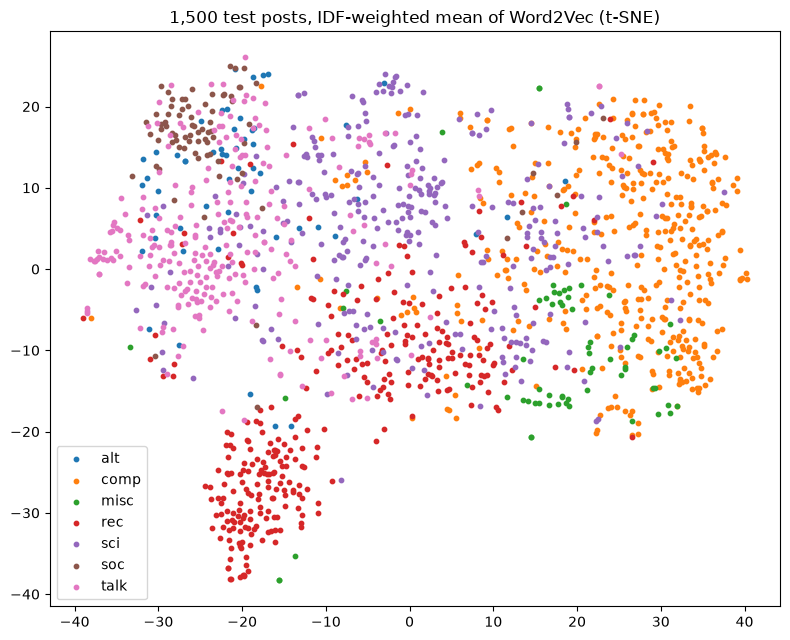

In [30]:
Y = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(normalize(idf_test))
test_group = group_of_class[test_y]

plt.figure(figsize=(8, 6.5))
for g, group in enumerate(group_names):
    plt.scatter(Y[test_group == g, 0], Y[test_group == g, 1], label=group, s=10)
plt.legend()
plt.title("1,500 test posts, IDF-weighted mean of Word2Vec (t-SNE)")
plt.tight_layout()
plt.show()

The posts of the same kind of newsgroup form regions: sports and vehicles (*rec*), computing (*comp*), science (*sci*),
religion and politics (*soc*, *talk*, *alt*). The regions overlap where the topics are close, for example religion and
politics. This is what the purity measures.

---
# Exercises

- **The window.** Rebuild the co-occurrence matrix with `WINDOW = 2` and with `WINDOW = 10`, apply PPMI and
  look at the neighbours of *game* and *space*. What kind of similarity does each window give?
- **Analogies.** Look for analogy questions that GloVe answers correctly and some it gets wrong, and try a
  question that involves a stereotype. Then try questions about computers or sports on our own vectors.
- **Weights.** The IDF weights help the mean. Try to remove the stopwords before averaging, or to use only the
  words with an IDF above a threshold. How does the purity change?
- **The vectors.** Compute the mean of the GloVe vectors, or of the FastText ones, instead of Word2Vec. Which
  vectors give the best document representation, and why could that be?
- **Doc2Vec.** Change the number of epochs, or use `dm=0` (the variant that predicts the words of the
  document). Is Doc2Vec better than the mean? How long does it take, compared with the mean?
- **Newsgroups.** Compute the purity separately for every newsgroup. Which groups are easy, and which are
  confused with each other? Do the methods fail on the same groups?
- **Queries.** Write other queries, and compare the posts found by TF-IDF and by the IDF-weighted mean. Find a
  query where the mean finds relevant posts that do not contain the words of the query.